# F1 / HERMES: Basic Exploratory Data Analysis
**Purpose:** explore weekly fashion popularity and matching influencer signals before model training.

This notebook follows the section-by-section style of the Google Trends EDA notebook. It checks structure and quality, plots trends, explores seasonality, compares paired signals, and prepares a forecasting plan.

**Run in VS Code:** save this notebook in `/Users/daki/Desktop/SEM 2/ML/Project`, alongside the `data` folder. Select your Python kernel and run cells from top to bottom.

Required files: `data/f1_main.csv` and `data/f1_fashion_forward.csv`.

Source: [authors' HERMES repository](https://github.com/etidav/HERMES/tree/main/data). F1 remains separate from Google Trends and VISUELLE. Series identifiers may describe groups, but their anonymous suffixes do not identify named microtrends such as polka dots. No findings are invented here: outputs are generated from your files.

## 1. Setup
Run the installation cell once if needed. The notebook needs only pandas, NumPy, Matplotlib and seaborn.

In [1]:
# Uncomment if packages are missing, then restart the kernel if requested.
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 10)
RANDOM_SEED = 42

## 2. Settings and file paths
The current project folder is tried first, followed by your Mac path. Outputs go into `outputs/f1_eda`; original files are never overwritten.

In [3]:
candidates = [Path.cwd(), Path.cwd().parent,
              Path("/Users/daki/Desktop/SEM 2/ML/Project")]
PROJECT_DIR = next((p for p in candidates if
                    (p / "data/f1_main.csv").exists() and
                    (p / "data/f1_fashion_forward.csv").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Put this notebook in Project and both CSV files in Project/data.")
DATA_DIR = PROJECT_DIR / "data"
OUT_DIR = PROJECT_DIR / "outputs/f1_eda"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_SIZE = 100  # plots and exploratory correlations; quality checks use all series
print("Project:", PROJECT_DIR)
print("Output:", OUT_DIR)
def save_plot(name):
    plt.savefig(OUT_DIR / name, dpi=160, bbox_inches="tight")

Project: /Users/daki/Desktop/SEM 2/ML/Project
Output: /Users/daki/Desktop/SEM 2/ML/Project/outputs/f1_eda


## 3. Load and inspect both files
Read the first column as the time index. Inspect it before assuming it contains calendar dates. Rows are expected to be time observations and columns series identifiers.

In [4]:
popularity = pd.read_csv(DATA_DIR / "f1_main.csv", index_col=0)
influencers = pd.read_csv(DATA_DIR / "f1_fashion_forward.csv", index_col=0)
for name, df in [("Popularity", popularity), ("Influencer", influencers)]:
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]:,} series")
    print("First index values:", df.index[:5].tolist())
    print("Last index values:", df.index[-5:].tolist())
    display(df.iloc[:5, :5])

Popularity: 261 rows x 10,000 series
First index values: ['2015-01-05', '2015-01-12', '2015-01-19', '2015-01-26', '2015-02-02']
Last index values: ['2019-12-02', '2019-12-09', '2019-12-16', '2019-12-23', '2019-12-30']


,br_female_outerwear_0,br_female_outerwear_1,br_female_outerwear_2,br_female_outerwear_3,br_female_outerwear_4
2015-01-05,0.014472,0.000000,0.000000,0.014472,0.000000
2015-01-12,0.000000,0.000000,0.000000,0.000000,0.029515
2015-01-19,0.000000,0.029996,0.014998,0.014998,0.029996
2015-01-26,0.011684,0.000000,0.000000,0.000000,0.005842
2015-02-02,0.006146,0.006146,0.006146,0.007170,0.016390


Influencer: 261 rows x 10,000 series
First index values: ['2015-01-05', '2015-01-12', '2015-01-19', '2015-01-26', '2015-02-02']
Last index values: ['2019-12-02', '2019-12-09', '2019-12-16', '2019-12-23', '2019-12-30']


,br_female_outerwear_0,br_female_outerwear_1,br_female_outerwear_2,br_female_outerwear_3,br_female_outerwear_4
2015-01-05,0.022968,0.010440,0.010440,0.014616,0.018792
2015-01-12,0.025582,0.016279,0.013954,0.020930,0.027907
2015-01-19,0.024387,0.022170,0.017736,0.028821,0.026604
2015-01-26,0.031788,0.020435,0.015894,0.043141,0.029517
2015-02-02,0.022019,0.019267,0.019267,0.019267,0.030277


## 4. Verify pairing and weekly dates
Stop if files do not have matching time indexes and series IDs. Dates are parsed only when the index looks like a calendar date; numeric indexes are kept as week positions rather than invented dates.

In [5]:
assert popularity.columns.is_unique and influencers.columns.is_unique, "Duplicate series IDs."
assert popularity.index.is_unique and influencers.index.is_unique, "Duplicate time indexes."
assert popularity.index.equals(influencers.index), "Time indexes differ: inspect before aligning."
assert set(popularity.columns) == set(influencers.columns), "Series IDs differ: inspect both files."
influencers = influencers.loc[:, popularity.columns]
raw_index = popularity.index.astype(str)
looks_dated = pd.Series(raw_index).str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}").all()
HAS_DATES = False
if looks_dated:
    dates = pd.to_datetime(raw_index, errors="coerce")
    if dates.notna().all():
        popularity.index = influencers.index = dates
        popularity = popularity.sort_index()
        influencers = influencers.reindex(popularity.index)
        HAS_DATES = True
print("Files paired successfully.")
if HAS_DATES:
    print("Date coverage:", popularity.index.min(), "to", popularity.index.max())
    print("Time-step counts (days):")
    display(popularity.index.to_series().diff().dt.days.value_counts())
else:
    print("Calendar dates not confirmed; plots will use sequential week positions.")
print("Numeric column types:", popularity.dtypes.value_counts().to_dict())

Files paired successfully.
Date coverage: 2015-01-05 00:00:00 to 2019-12-30 00:00:00
Time-step counts (days):


7.0    260
Name: count, dtype: int64

Numeric column types: {dtype('float64'): 10000}


## 5. Data quality
Check missing/non-numeric values, infinities, zero shares, constant series and exact duplicate curves. A high zero share is a flag to inspect, not an automatic reason to remove an emerging trend. Keep viral spikes unless there is evidence of an error.

In [6]:
popularity = popularity.apply(pd.to_numeric, errors="coerce")
influencers = influencers.apply(pd.to_numeric, errors="coerce")
def quality(df):
    a = df.to_numpy(dtype=float)
    return pd.Series({"weeks":len(df), "series":df.shape[1],
        "missing_values":int(df.isna().sum().sum()),
        "infinite_values":int(np.isinf(a).sum()),
        "negative_values":int((a < 0).sum()),
        "constant_or_empty_series":int((df.nunique() <= 1).sum()),
        "exact_duplicate_curves":int(df.T.duplicated().sum()),
        "zero_share":float((df == 0).to_numpy().mean()),
        "memory_MB":df.memory_usage(deep=True).sum()/1024**2})
quality_table = pd.DataFrame({"popularity":quality(popularity), "influencers":quality(influencers)})
display(quality_table.round(4))
quality_table.to_csv(OUT_DIR / "quality_summary.csv")
# Replace infinities for exploration; leave missing values unfilled.
popularity = popularity.replace([np.inf, -np.inf], np.nan)
influencers = influencers.replace([np.inf, -np.inf], np.nan)

,popularity,influencers
weeks,261.0000,261.0000
series,10000.0000,10000.0000
missing_values,0.0000,0.0000
infinite_values,0.0000,0.0000
negative_values,0.0000,0.0000
constant_or_empty_series,0.0000,0.0000
exact_duplicate_curves,0.0000,7181.0000
zero_share,0.0103,0.0446
memory_MB,19.9226,19.9226


## 6. Summary statistics and distributions
Summarize each popularity curve. Values are supplied in normalized form; they are not sales counts or Google Trends scores. Do not interpret levels as absolute audience size.

,mean,std,min,max,missing_share,zero_share,unique_values,peak_to_mean
br_female_outerwear_0,0.010,0.005,0.000,0.032,0.0,0.008,260,3.083
br_female_outerwear_1,0.015,0.006,0.000,0.033,0.0,0.011,259,2.214
br_female_outerwear_2,0.012,0.005,0.000,0.026,0.0,0.011,259,2.110
br_female_outerwear_3,0.009,0.004,0.000,0.026,0.0,0.008,260,2.918
br_female_outerwear_4,0.030,0.011,0.000,0.059,0.0,0.004,261,1.975
br_female_outerwear_5,0.020,0.008,0.000,0.039,0.0,0.008,260,1.987
br_female_outerwear_6,0.026,0.010,0.000,0.050,0.0,0.004,261,1.947
br_female_outerwear_7,0.006,0.003,0.000,0.018,0.0,0.042,251,2.803
br_female_outerwear_8,0.008,0.004,0.000,0.021,0.0,0.019,257,2.518
br_female_outerwear_9,0.025,0.010,0.009,0.063,0.0,0.000,261,2.534


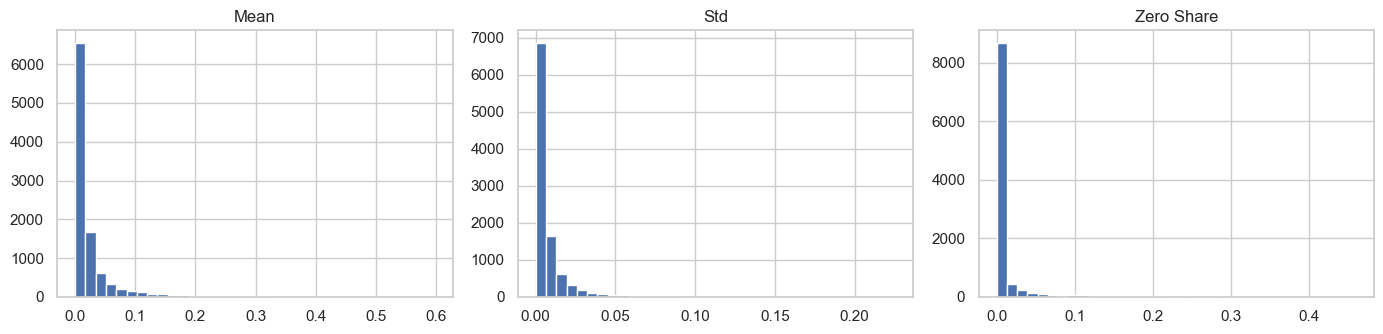

In [7]:
summary = pd.DataFrame({"mean":popularity.mean(), "std":popularity.std(),
    "min":popularity.min(), "max":popularity.max(),
    "missing_share":popularity.isna().mean(), "zero_share":popularity.eq(0).mean(),
    "unique_values":popularity.nunique()})
summary["peak_to_mean"] = summary["max"] / summary["mean"].replace(0, np.nan)
display(summary.round(3).head(10))
summary.to_csv(OUT_DIR / "series_summary.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, field in zip(axes, ["mean", "std", "zero_share"]):
    summary[field].dropna().hist(bins=35, ax=ax)
    ax.set_title(field.replace("_", " ").title())
plt.tight_layout(); save_plot("01_distributions.png"); plt.show()

## 7. Sample popularity curves
Use a reproducible random sample, rather than selecting only attractive-looking trends. Group-like identifiers are displayed verbatim; decoding them requires documentation.

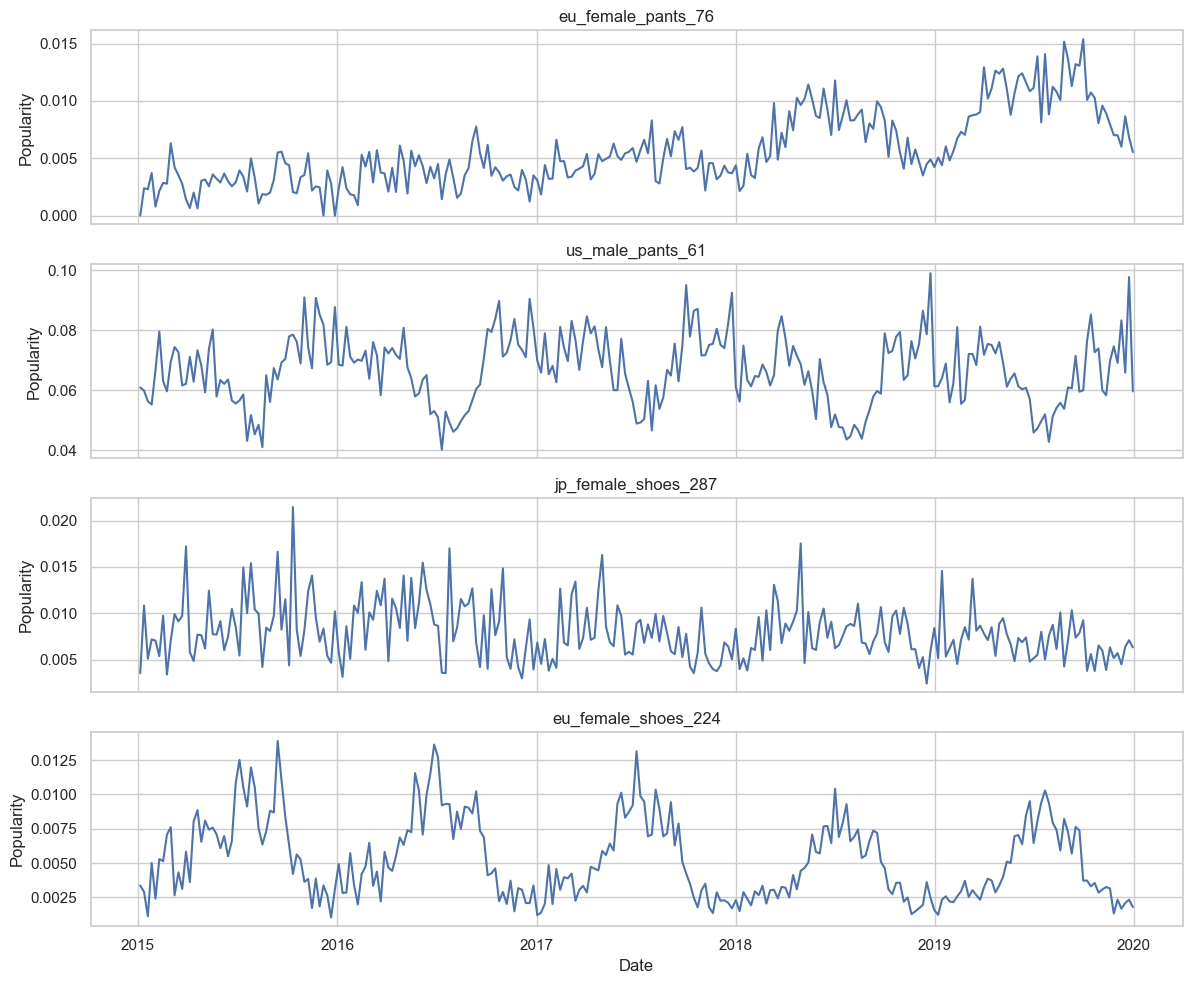

In [8]:
eligible = summary.index[(summary["unique_values"] > 1) & (summary["missing_share"] == 0)].tolist()
if not eligible:
    raise ValueError("No complete variable popularity series; inspect missing data before continuing.")
rng = np.random.default_rng(RANDOM_SEED)
sample_cols = rng.choice(eligible, size=min(SAMPLE_SIZE, len(eligible)), replace=False).tolist()
x = popularity.index if HAS_DATES else np.arange(len(popularity))
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, sample_cols[:4]):
    ax.plot(x, popularity[col], linewidth=1.5)
    ax.set_title(col); ax.set_ylabel("Popularity")
axes[-1].set_xlabel("Date" if HAS_DATES else "Week position (0 = first observation)")
plt.tight_layout(); save_plot("02_sample_curves.png"); plt.show()

## 8. Popularity versus influencer signal
Each panel compares the same identifier in both files. Visual lead/lag patterns suggest questions to test; they do not establish causation.

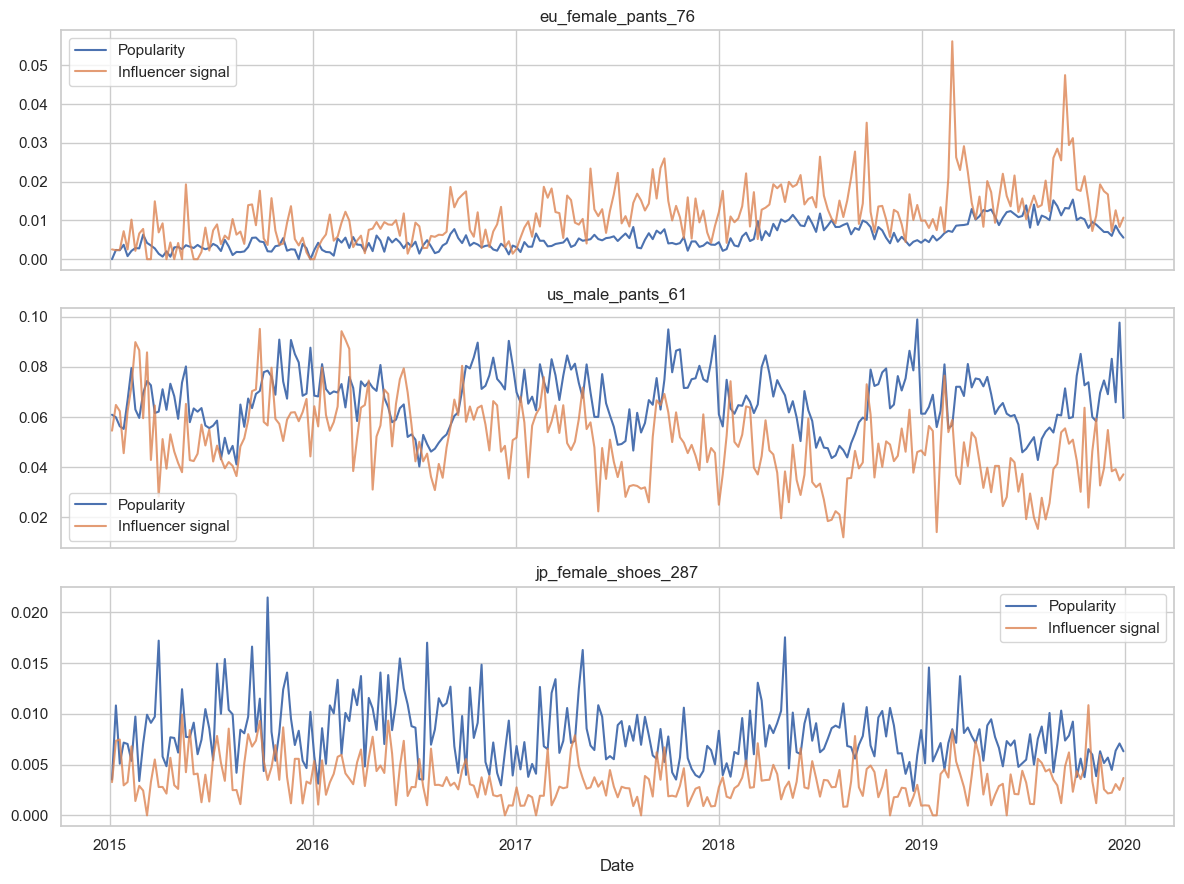

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, col in zip(axes, sample_cols[:3]):
    ax.plot(x, popularity[col], label="Popularity")
    ax.plot(x, influencers[col], label="Influencer signal", alpha=0.8)
    ax.set_title(col); ax.legend()
axes[-1].set_xlabel("Date" if HAS_DATES else "Week position")
plt.tight_layout(); save_plot("03_paired_signals.png"); plt.show()

## 9. Exploratory lead–lag relationships (early data only)
Reserve the final 15% for later testing. Use the first 70% for exploration and the next 15% for validation. At lag k, correlate influencer changes k weeks earlier with current popularity changes. Positive lags mean the influencer signal comes first. Use changes to reduce correlations driven by shared levels. This sample analysis is descriptive, not evidence of improved forecasting.

Influencer lead (weeks),0,1,2,3,4,5,6,7,8
count,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000
mean,0.058,-0.006,0.015,0.000,0.019,0.002,0.010,0.001,-0.008
std,0.125,0.103,0.104,0.101,0.100,0.092,0.083,0.084,0.094
min,-0.162,-0.414,-0.236,-0.215,-0.194,-0.198,-0.189,-0.195,-0.231
25%,-0.028,-0.066,-0.057,-0.068,-0.053,-0.072,-0.054,-0.053,-0.081
50%,0.054,-0.000,0.021,-0.014,0.012,0.018,0.011,-0.006,0.002
75%,0.123,0.068,0.090,0.075,0.087,0.061,0.066,0.057,0.065
max,0.503,0.239,0.274,0.262,0.366,0.194,0.218,0.221,0.173


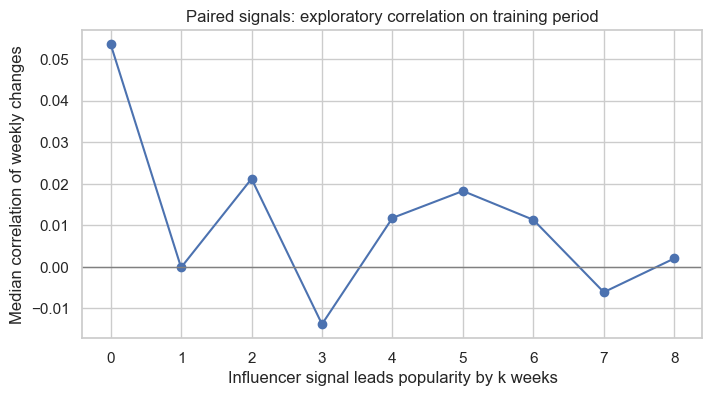

In [10]:
n = len(popularity)
train_end, val_end = int(n * 0.70), int(n * 0.85)
assert train_end > 16 and val_end > train_end, "Not enough observations."
train_pop = popularity.iloc[:train_end]
train_inf = influencers.iloc[:train_end]
lag_correlations = pd.DataFrame({lag: train_inf[sample_cols].diff().shift(lag).corrwith(
    train_pop[sample_cols].diff()) for lag in range(9)})
lag_correlations.columns.name = "Influencer lead (weeks)"
display(lag_correlations.describe().round(3))
lag_correlations.median().plot(marker="o", figsize=(8, 4))
plt.axhline(0, color="grey", linewidth=1)
plt.xlabel("Influencer signal leads popularity by k weeks")
plt.ylabel("Median correlation of weekly changes")
plt.title("Paired signals: exploratory correlation on training period")
save_plot("04_lead_lag.png"); plt.show()
lag_correlations.to_csv(OUT_DIR / "training_lead_lag_correlations.csv")

## 10. Seasonality and recent changes (training period)
Lag-52 autocorrelation is a possible yearly-seasonality indicator on weekly observations, not proof. Recent changes compare two four-week averages, avoiding division by zero. Rankings describe movement within each normalized series, not absolute popularity between series.

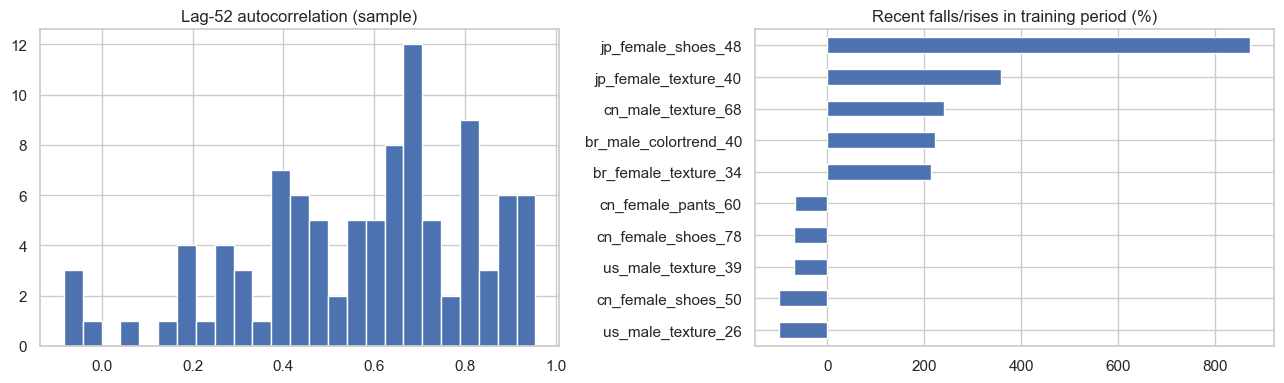

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if len(train_pop) >= 104:
    acf52 = train_pop[sample_cols].apply(lambda s: s.autocorr(lag=52))
    acf52.dropna().hist(bins=25, ax=axes[0])
    axes[0].set_title("Lag-52 autocorrelation (sample)")
else:
    axes[0].text(0.1, 0.5, "Insufficient history for yearly check")
past = train_pop.iloc[-8:-4].mean()
recent = train_pop.iloc[-4:].mean()
growth = (recent / past.where(past > 0) - 1).replace([np.inf, -np.inf], np.nan).dropna().sort_values()
selected = pd.concat([growth.head(5), growth.tail(5)]).loc[lambda s: ~s.index.duplicated()]
selected.mul(100).plot.barh(ax=axes[1])
axes[1].set_title("Recent falls/rises in training period (%)")
plt.tight_layout(); save_plot("05_seasonality_growth.png"); plt.show()

## 11. Define a rising label and inspect class balance
Example target: next four weeks' mean / latest four weeks' mean. Only use labels whose outcome is wholly inside the training period when choosing thresholds. Very small denominators can exaggerate growth; the minimum level below is exploratory and must be justified on training data. Future values are labels only, never input features.

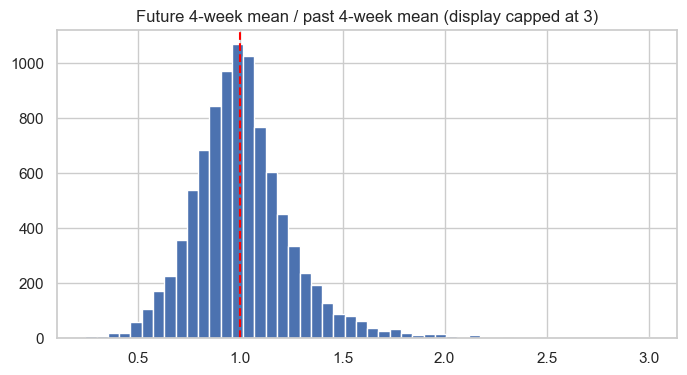

Growth > 10%    0.291947
Growth > 19%    0.172238
Growth > 30%    0.101476
Growth > 50%    0.038637
Name: Share of valid training examples, dtype: float64

In [12]:
past_4 = train_pop[sample_cols].rolling(4, min_periods=4).mean()
future_4 = past_4.shift(-4)
MIN_PAST_LEVEL = 0.01  # inspect scale and tune only on training/validation data
ratio = future_4 / past_4.where(past_4 > MIN_PAST_LEVEL)
values = ratio.stack().replace([np.inf, -np.inf], np.nan).dropna()
if len(values):
    values.clip(0, 3).hist(bins=50, figsize=(8, 4))
    plt.axvline(1, color="red", linestyle="--")
    plt.title("Future 4-week mean / past 4-week mean (display capped at 3)")
    save_plot("06_growth_ratios.png"); plt.show()
    display(pd.Series({f"Growth > {int((t-1)*100)}%": (values > t).mean()
                       for t in [1.1, 1.2, 1.3, 1.5]}, name="Share of valid training examples"))
else:
    print("No valid growth ratios; inspect scale and MIN_PAST_LEVEL.")

## 12. Forecasting experiment plan
Train the same model family twice: **popularity history only**, then **popularity history + past influencer signals**. Predict 4 and 8 weeks ahead. Compare against last value and four-week-average baselines using MAE and MASE. Influencer values from the forecast period are unavailable and must not be used.

Use chronological splits with no shuffling. Drop training/validation examples whose future target extends beyond that split boundary. Historical observations before a test origin may be used as inputs. Fit imputers/scalers on training data only. Normalization supplied by the authors may have used full-history information; inspect their methodology and acknowledge this limitation.

In [13]:
split_table = pd.DataFrame([
    {"split":"Train", "start_position":0, "end_position":train_end-1, "weeks":train_end},
    {"split":"Validation", "start_position":train_end, "end_position":val_end-1, "weeks":val_end-train_end},
    {"split":"Test", "start_position":val_end, "end_position":n-1, "weeks":n-val_end}])
display(split_table)
split_table.to_csv(OUT_DIR / "proposed_splits.csv", index=False)
print("For horizon h, a training origin t requires t + h < train_end.")
print("Final test-period modeling decisions remain untouched by this exploratory analysis.")

,split,start_position,end_position,weeks
0,Train,0,181,182
1,Validation,182,220,39
2,Test,221,260,40


For horizon h, a training origin t requires t + h < train_end.
Final test-period modeling decisions remain untouched by this exploratory analysis.


## 13. Save an initial findings note
This generates factual counts from your files. Add your interpretation after inspecting the plots. No automatic deletion of spikes, sparse series, or duplicate curves is performed. Summary files are EDA outputs, not final model-ready data.

In [14]:
note = f"""# F1 EDA: initial findings
- Popularity table: {len(popularity):,} observations and {popularity.shape[1]:,} series.
- Both files have matching time indexes and aligned series identifiers.
- Calendar dates confirmed: {HAS_DATES}.
- Popularity missing values after infinity handling: {popularity.isna().sum().sum():,}.
- Influencer missing values after infinity handling: {influencers.isna().sum().sum():,}.
- Complete variable popularity series: {len(eligible):,}.
- Paired-signal exploratory sample: {len(sample_cols)} series.
- No raw input files were changed; spikes were retained.

## Interpretation to complete
1. Describe patterns in the sample curves.
2. Describe the training-period lead-lag plot without claiming causation.
3. Describe sparse/constant/duplicate series and a justified handling policy.
4. Confirm source normalization, time frequency, coverage and usage terms.
5. State whether 4-/8-week forecasting and the influencer comparison are feasible.

## Role in our project
Separate social-media benchmark; not a direct join with named Google Trends keywords.
"""
(OUT_DIR / "initial_findings.md").write_text(note, encoding="utf-8")
print(note)
print("Saved tables, charts and findings to:", OUT_DIR)

# F1 EDA: initial findings
- Popularity table: 261 observations and 10,000 series.
- Both files have matching time indexes and aligned series identifiers.
- Calendar dates confirmed: True.
- Popularity missing values after infinity handling: 0.
- Influencer missing values after infinity handling: 0.
- Complete variable popularity series: 10,000.
- Paired-signal exploratory sample: 100 series.
- No raw input files were changed; spikes were retained.

## Interpretation to complete
1. Describe patterns in the sample curves.
2. Describe the training-period lead-lag plot without claiming causation.
3. Describe sparse/constant/duplicate series and a justified handling policy.
4. Confirm source normalization, time frequency, coverage and usage terms.
5. State whether 4-/8-week forecasting and the influencer comparison are feasible.

## Role in our project
Separate social-media benchmark; not a direct join with named Google Trends keywords.

Saved tables, charts and findings to: /Users/daki/De

## Conclusion from the F1 EDA

The F1 dataset is suitable for our **social-media forecasting experiment**. It contains **10,000 fashion-popularity series and matching influencer signals**, covering **261 weeks from 5 January 2015 to 30 December 2019**. We will investigate whether influencer activity improves fashion-popularity forecasts **4–8 weeks ahead**.

### 1. Available Data and Its Purpose

| Available data | How it helps the project |
|---|---|
| Weekly dates | Establish chronological order, create historical features, and split earlier training data from later testing data. |
| Fashion-popularity values | Supply historical inputs and the future values the model will predict. |
| Matching influencer signals | Allow us to compare forecasting with and without influencer information. |
| Series identifiers | Match popularity curves to their corresponding influencer signals. Specific microtrend names cannot be identified from the anonymous IDs. |

### 2. Main EDA Findings

- **Consistent structure:** Both files contain 261 observations and 10,000 series, with matching dates and identifiers.
- **Regular weekly observations:** All consecutive dates are seven days apart.
- **Good basic data quality:** Neither file contains missing, infinite, negative, or constant values.
- **Distinct popularity curves:** No exact duplicate popularity series were found.
- **Shared influencer signals:** There are **2,819 distinct influencer curves**, with 7,181 duplicate columns beyond their first occurrences. We need to investigate how these signals were constructed before deciding whether any special handling is necessary.
- **Relatively few zero values:** Approximately **1.03% of popularity values** and **4.46% of influencer values** are zero. Individual series still require inspection.
- **Weak overall lead–lag correlations:** In the 100-series training sample, correlations between earlier influencer changes and later popularity changes were generally close to zero. Influencer information may still help some forecasts, but this must be tested.
- **Strong growth is less common:** Approximately **17% of eligible sampled training examples** showed more than 20% growth in the following four-week average. This depends on the sample and minimum-interest filter.
- **Seasonality requires further testing:** Lag-52 autocorrelation was explored as an indicator of annual patterns. We cannot assume that every series is seasonal.

### 3. Planned Features and Their Purpose

These features will be calculated from the available data during model preparation.

| Planned feature | Purpose |
|---|---|
| Popularity lags of 1, 2, 4 and 8 weeks | Capture recent history and changes in popularity. |
| Four- and eight-week rolling averages | Reduce short-term noise and describe the underlying direction. |
| Recent growth and slope | Identify increasing, declining, or accelerating popularity. |
| Rolling standard deviation | Measure stability and volatility. |
| Past influencer values and changes | Test whether earlier influencer activity helps predict later popularity. |
| Week of year and lag-52 popularity | Capture recurring seasonal patterns where sufficient history exists. |

All features will use **only information available before the forecast date**. Future popularity values will be used as targets, and future influencer values will not be used as inputs.

### 4. Role and Limitations

F1 provides a separate social-media forecasting experiment alongside Google Trends and VISUELLE. We will compare:

- **Model A:** popularity history and calendar features.
- **Model B:** the same inputs plus past influencer signals.

The dataset measures normalized social-media popularity rather than purchases. Its history ends in 2019, and its anonymous trend identifiers prevent direct matching to named Google Trends keywords or VISUELLE products. It therefore cannot directly identify which named styles to stock.

The 10,000 series should not be treated as fully independent, especially because some share influencer signals. We must also verify the authors’ normalization method before making claims about forecasting performance.

### 5. Next Steps

1. Verify the documentation on influencer-signal construction, normalization, and usage terms.
2. Use chronological splits: provisionally **182 training weeks, 39 validation weeks, and 40 test weeks**.
3. Exclude training and validation examples whose future targets cross split boundaries.
4. Establish last-value and four-week-average forecasting baselines.
5. Create historical features and train regularized regression and gradient-boosted trees.
6. Compare models with and without past influencer signals on identical examples.
7. Evaluate **4- and 8-week forecasts** using **MAE and MASE**.
8. Analyze performance across stable, volatile, and strongly growing series.

**Overall, the EDA confirms that F1 is usable for our proposed experiment. Model evaluation will determine whether influencer signals provide additional predictive value.**